In [3]:
import pandas as pd

df_rpk = pd.read_csv('All_source_plates_mapped_rpk_column_names_standardized_unique_identifiers_for_duplicates_with_hbdb_plate_samples_dropped_less_100k_readcounts_071426.csv').set_index('peptide')

In [4]:
first_tp = pd.read_csv('earliest_tp_rpk_avg_value_for_cohort_techreps_071626.csv').set_index('peptide')

In [5]:
first_tp.filter(regex=('S-'), axis=1).shape

first_tp.filter(regex=('C-'), axis=1).shape

(90132, 277)

In [6]:
first_tp_sample_ids = first_tp.columns.to_list()

In [7]:
first_tp.shape

(90132, 397)

In [8]:
# For C-/H-/S- samples: strip one trailing _N (technical replicate suffix)
# For AG/Canary/mAb: strip ALL trailing _N or _sN segments so they all collapse to their base name
def get_prefix(col):
    if re.match(r'^(AG|Canary|mAb)', col):
        return re.sub(r'(_s?\d+)+$', '', col)
    else:
        return re.sub(r'_\d+$', '', col) #this starts removing from the end of the string, $ means end, \d one or more digits, _ underscore

import re
prefix = df_rpk.columns.map(get_prefix)

In [9]:
df_rpk.columns = df_rpk.columns.map(get_prefix)

In [10]:
df_rpk.head(2)

,C-452-2_5_H3,C-109-3_4_E7,C-109-3_4_E7,C-111-3_3_I6,C-111-3_3_I6,C-112-1_3_B3,C-112-1_3_B3,C-112-2_7_G7,C-112-2_7_G7,C-114-2_7_B1,...,HBDB-109,HBDB-109,HBDB-111,HBDB-111,HBDB-115,HBDB-115,mAb,mAb,mAb,mAb
peptide,,,,,,,,,,,,,,,,,,,,,
WFG38034.1|precursor|Aba-Mianyang_virus|SC/C3-30.18/2021|Ochotona_sp.|China|Aug-2021|S|?|tile_1,0.0,0.0,0.0,0.870155,0.0,0.0,0.918952,0.368368,0.000000,0.0,...,0.000000,0.0,0.0,0.255092,0.00000,0.0,0.0,0.0,0.178464,0.59977
WFG38034.1|precursor|Aba-Mianyang_virus|SC/C3-30.18/2021|Ochotona_sp.|China|Aug-2021|S|?|tile_2,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.580242,0.0,...,0.214736,0.0,0.0,0.255092,0.68292,0.0,0.0,0.0,0.000000,0.00000


### subset to only first timepoints in cohort

In [11]:
df_rpk_with_techreps_first_tp = df_rpk.loc[:, df_rpk.columns.isin(first_tp_sample_ids)]

In [12]:
import pandas as pd
from itertools import combinations

tech_corr = []

for name in df_rpk_with_techreps_first_tp.columns.unique():
    cols = df_rpk_with_techreps_first_tp.loc[:, df_rpk_with_techreps_first_tp.columns == name]
    if cols.shape[1] > 1:
        for i, j in combinations(range(cols.shape[1]), 2):
            r = cols.iloc[:, i].corr(cols.iloc[:, j])
            tech_corr.append({
                "sample": name,
                "correlation": r
            })

tech_corr = pd.DataFrame(tech_corr)


In [13]:
tech_corr['sample'].unique()

array(['C-109-3_4_E7', 'C-111-3_3_I6', 'C-112-1_3_B3', 'C-130-2_3_C3',
       'C-135-2_1_D2', 'C-140-1_1_A7', 'C-144-2_2_B5', 'C-147-2_1_F5',
       'C-150-2_1_H3', 'C-183-1_1_F4', 'C-192-3_1_D3', 'C-434-3_5_E2',
       'C-438-1_3_A4', 'C-441-3_2_G4', 'C-444-2_2_E4', 'C-464-3_3_F9',
       'C-467-3_2_D5', 'C-470-3_2_F8', 'C-475-2_2_F5', 'C-483-1_1_D9',
       'C-484-2_3_D4', 'C-485-3_2_H3', 'C-489-2_3_D5', 'C-499-3_1_B2',
       'C-505-2_4_C2', 'C-508-2_4_A8', 'S-107_SA1_A9', 'S-113_SA1_B4',
       'S-114_SA1_B5', 'S-115_SA1_A5', 'S-125_SA1_C3', 'S-126_SA1_C4',
       'S-148_SA1_E7', 'S-186_SA1_G3', 'S-463_SA2_F8', 'S-488_SA1_H2',
       'S-502_SA4_I1', 'S-509_SA3_H6', 'C-109-1_5_B3', 'C-114-3_3_B6',
       'C-115-3_1_D6', 'C-122-2_3_B8', 'C-137-3_2_A9', 'C-139-2_6_D5',
       'C-145-2_2_A6', 'C-145-3_1_E4', 'C-148-3_1_G3', 'C-178-1_1_E1',
       'C-448-1_1_I4', 'C-449-3_7_E4', 'C-462-2_2_D4', 'C-462-3_2_I6',
       'C-465-3_5_G8', 'C-467-1_2_D6', 'C-472-3_2_E9', 'C-475-1_3_G6',
      

In [14]:
print(type(tech_corr))

<class 'pandas.core.frame.DataFrame'>


In [15]:
#number of unique techrep samples

num_unique_techreps = tech_corr['sample'].nunique()

In [16]:
num_unique_techreps

100

### now calculate pearson correlation between samples (techreps already averaged)

In [17]:
import pandas as pd
from itertools import combinations

nontech_corr_all = []

for sample1, sample2 in combinations(first_tp.columns, 2):
    r = first_tp[sample1].corr(first_tp[sample2], method="pearson")
    nontech_corr_all.append(r)




## Now combine the two dataframes for plotting

In [18]:
import pandas as pd

corr_df = pd.DataFrame({
    "correlation": tech_corr["correlation"].to_list() + nontech_corr_all,
    "group": (
        ["Technical replicates"] * len(tech_corr) +
        ["Between individuals"] * len(nontech_corr_all)
    )
})

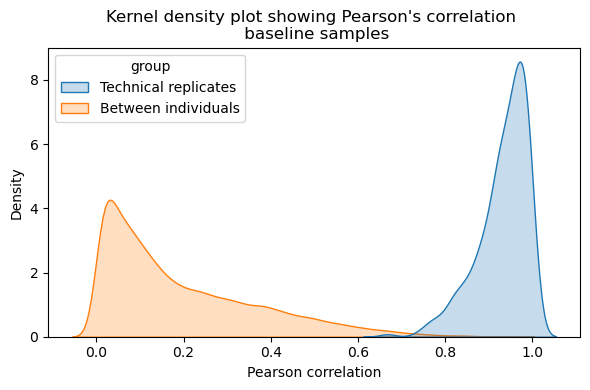

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.kdeplot(
    data=corr_df,
    x="correlation",
    hue="group",
    fill=True,
    common_norm=False
)
plt.xlabel("Pearson correlation")
plt.title("Kernel density plot showing Pearson's correlation \n baseline samples")


plt.savefig(".kernel_density_plot_071626.svg", format='svg')

plt.tight_layout()
plt.show()



In [20]:
len(first_tp_sample_ids)

397